In [17]:
# Dataset
# https://www.kaggle.com/code/ginelledsouza/stroke-analysis

In [1]:
# Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120
RND = 2026  # random seed

# Load Data function
def Load_Data(path='healthcare-dataset-stroke-data.csv'):
    return pd.read_csv(path)

# Load the dataset
data = Load_Data('healthcare-dataset-stroke-data.csv')

# Remove rows where 'bmi' is missing and save to new file
data_clean = data.dropna(subset=['bmi'])
data_clean.to_csv('healthcare_dataset_stroke.csv', index=False)

# Reload the newly saved dataset
data = pd.read_csv('healthcare_dataset_stroke.csv')

# Check missing values & dataset overview
def overview(df):
    print("Rows / Columns:", df.shape)
    print("\nColumn types:\n", df.dtypes)
    print("\nMissing values per column:\n", df.isna().sum())
    print("\nDescriptive summary (numeric columns):\n", df.describe().T)

overview(data)

print("\nDuplicate rows count:", data.duplicated().sum())

# Display the first few rows (Jupyter will format this cleanly)
data.head()

Rows / Columns: (4909, 12)

Column types:
 id                     int64
gender                   str
age                  float64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object

Missing values per column:
 id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Descriptive summary (numeric columns):
                     count          mean           std    min       25%  \
id                 4909.0  37064.313506  20995.098457  77.00  18605.00   
age                4909.0     42.865374     22.555115   0.08     25.00   
hypertension  

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


# Exploratory Stroke Data Analysis

C:\Users\HP\AppData\Local\Temp\ipykernel_8540\3187583630.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_8540\3187583630.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_8540\3187583630.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_8540\3187583630.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and se

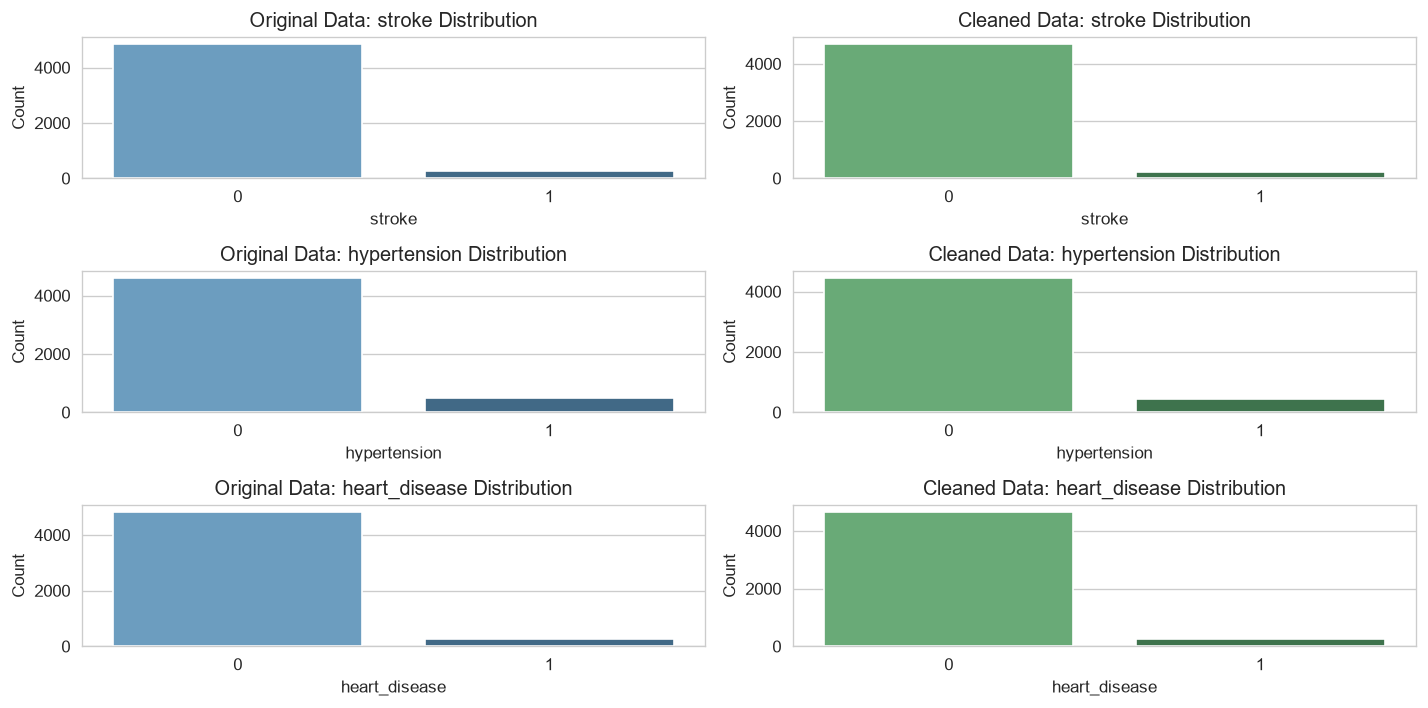

--- Original Target Class Ratio (%) ---
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

--- Cleaned Target Class Ratio (%) ---
stroke
0    95.742514
1     4.257486
Name: proportion, dtype: float64


In [2]:
# Both Datasets
df_clean = Load_Data(path='healthcare_dataset_stroke.csv')
df_original = pd.read_csv('healthcare-dataset-stroke-data.csv')
# Define target variable and key categorical features to compare
features = ['stroke', 'hypertension', 'heart_disease']

fig, axes = plt.subplots(len(features), 2, figsize=(12, 2 * len(features)))

for i, feature in enumerate(features):
    # Plot Original Data Distribution
    sns.countplot(
        data=df_original, 
        x=feature, 
        ax=axes[i, 0], 
        palette='Blues_d'
    )
    axes[i, 0].set_title(f'Original Data: {feature} Distribution')
    axes[i, 0].set_xlabel(feature)
    axes[i, 0].set_ylabel('Count')

    # Plot Cleaned Data Distribution
    sns.countplot(
        data=df_clean, 
        x=feature, 
        ax=axes[i, 1], 
        palette='Greens_d'
    )
    axes[i, 1].set_title(f'Cleaned Data: {feature} Distribution')
    axes[i, 1].set_xlabel(feature)
    axes[i, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Print exact class proportion percentages for comparison
print("--- Original Target Class Ratio (%) ---")
print(df_original['stroke'].value_counts(normalize=True) * 100)

print("\n--- Cleaned Target Class Ratio (%) ---")
print(df_clean['stroke'].value_counts(normalize=True) * 100)


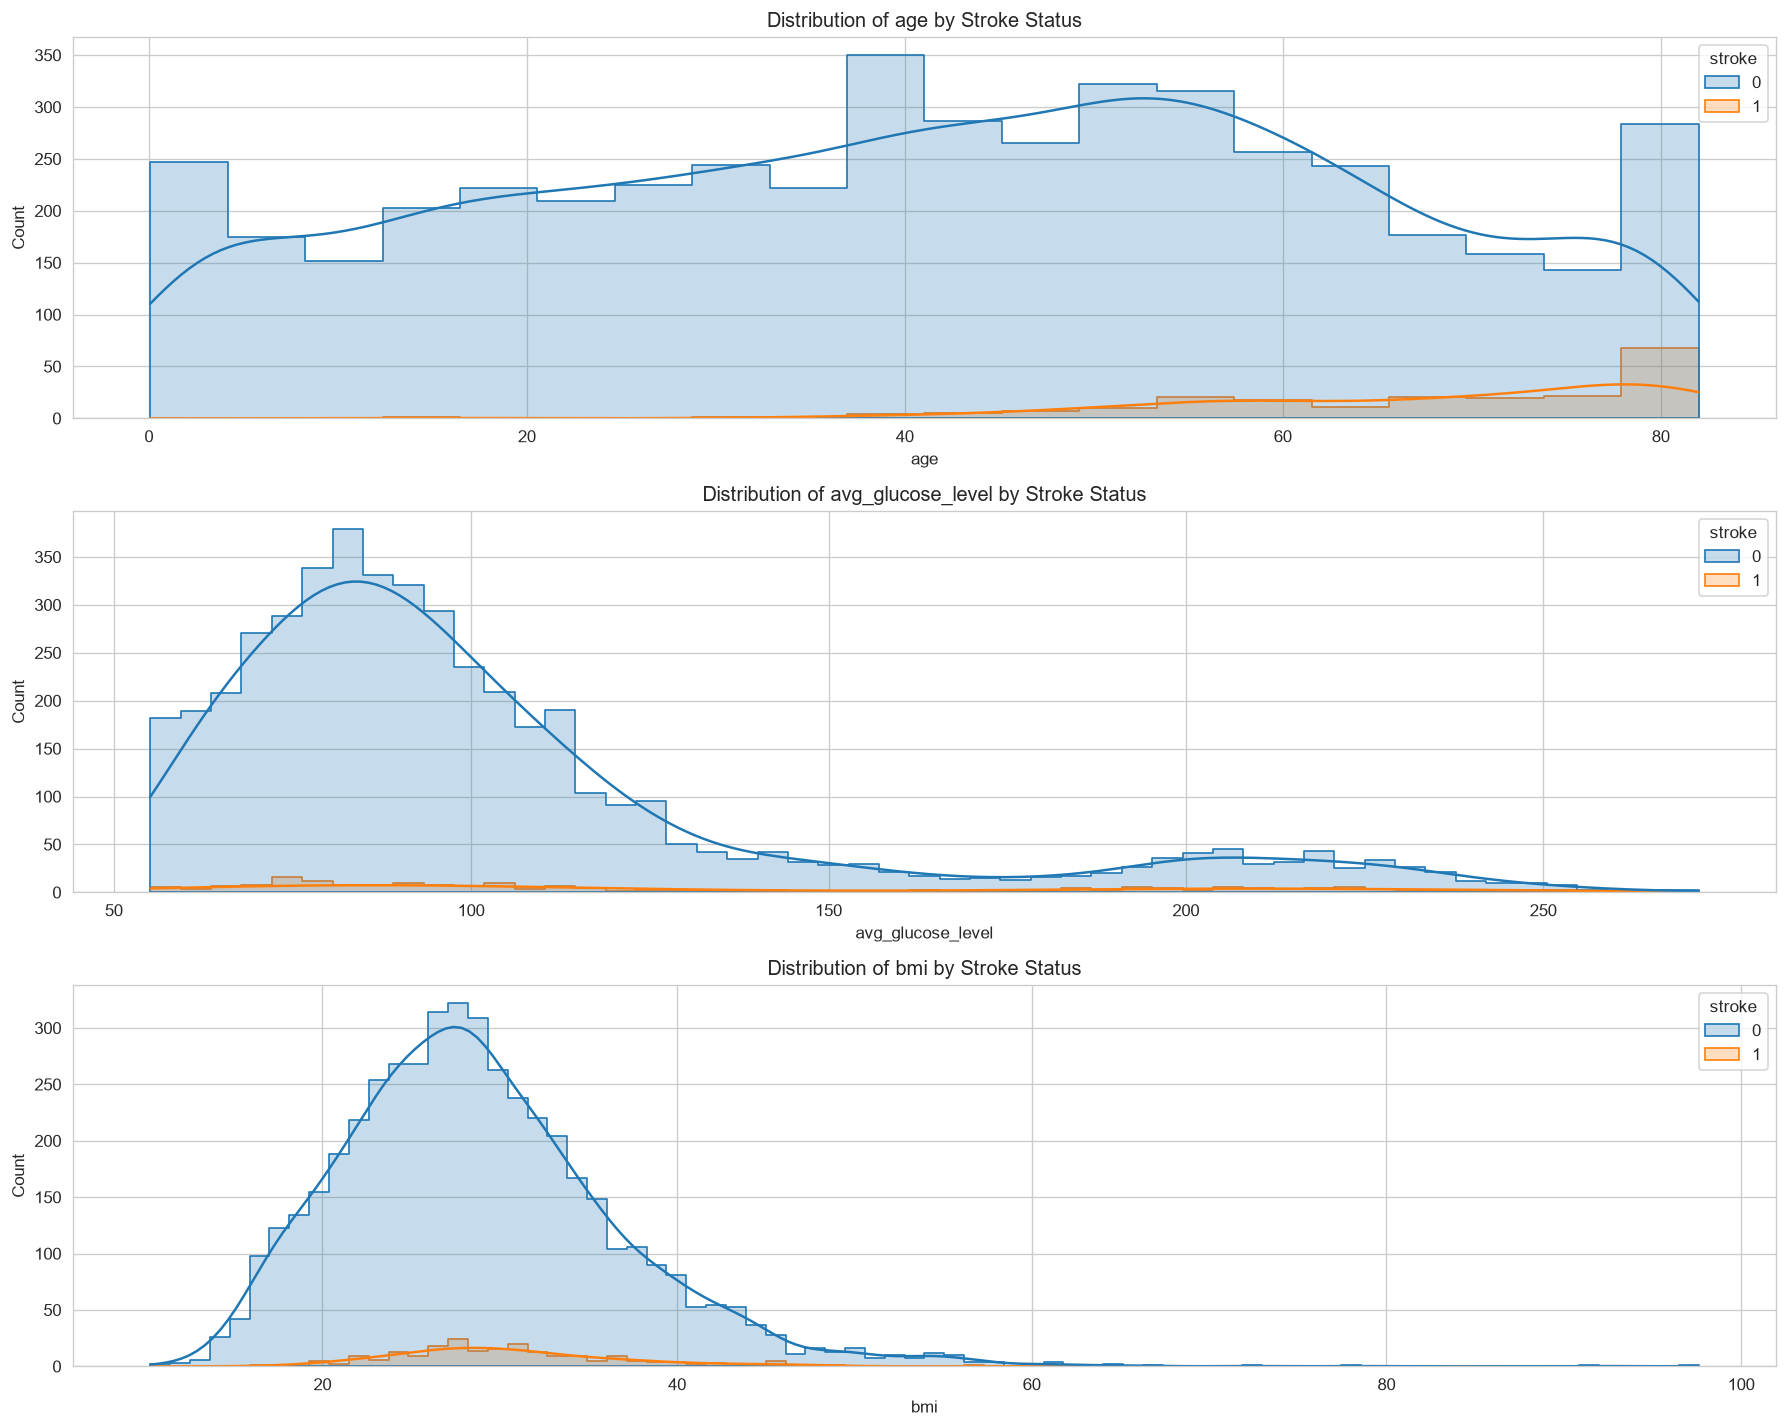

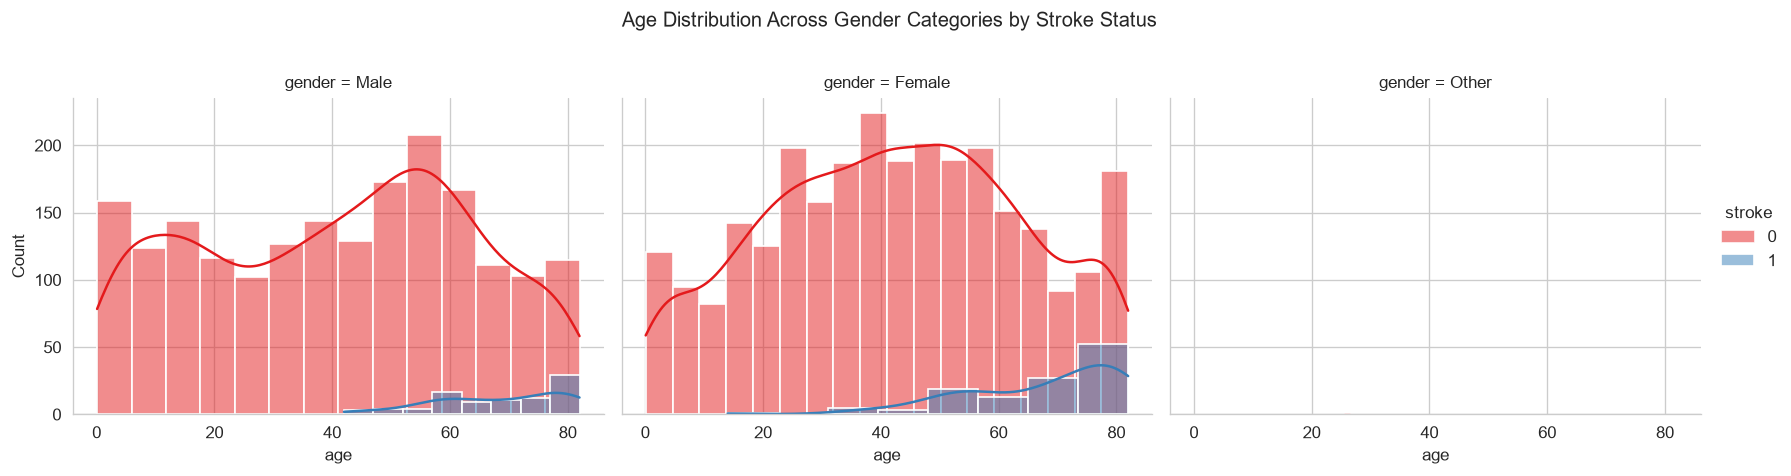

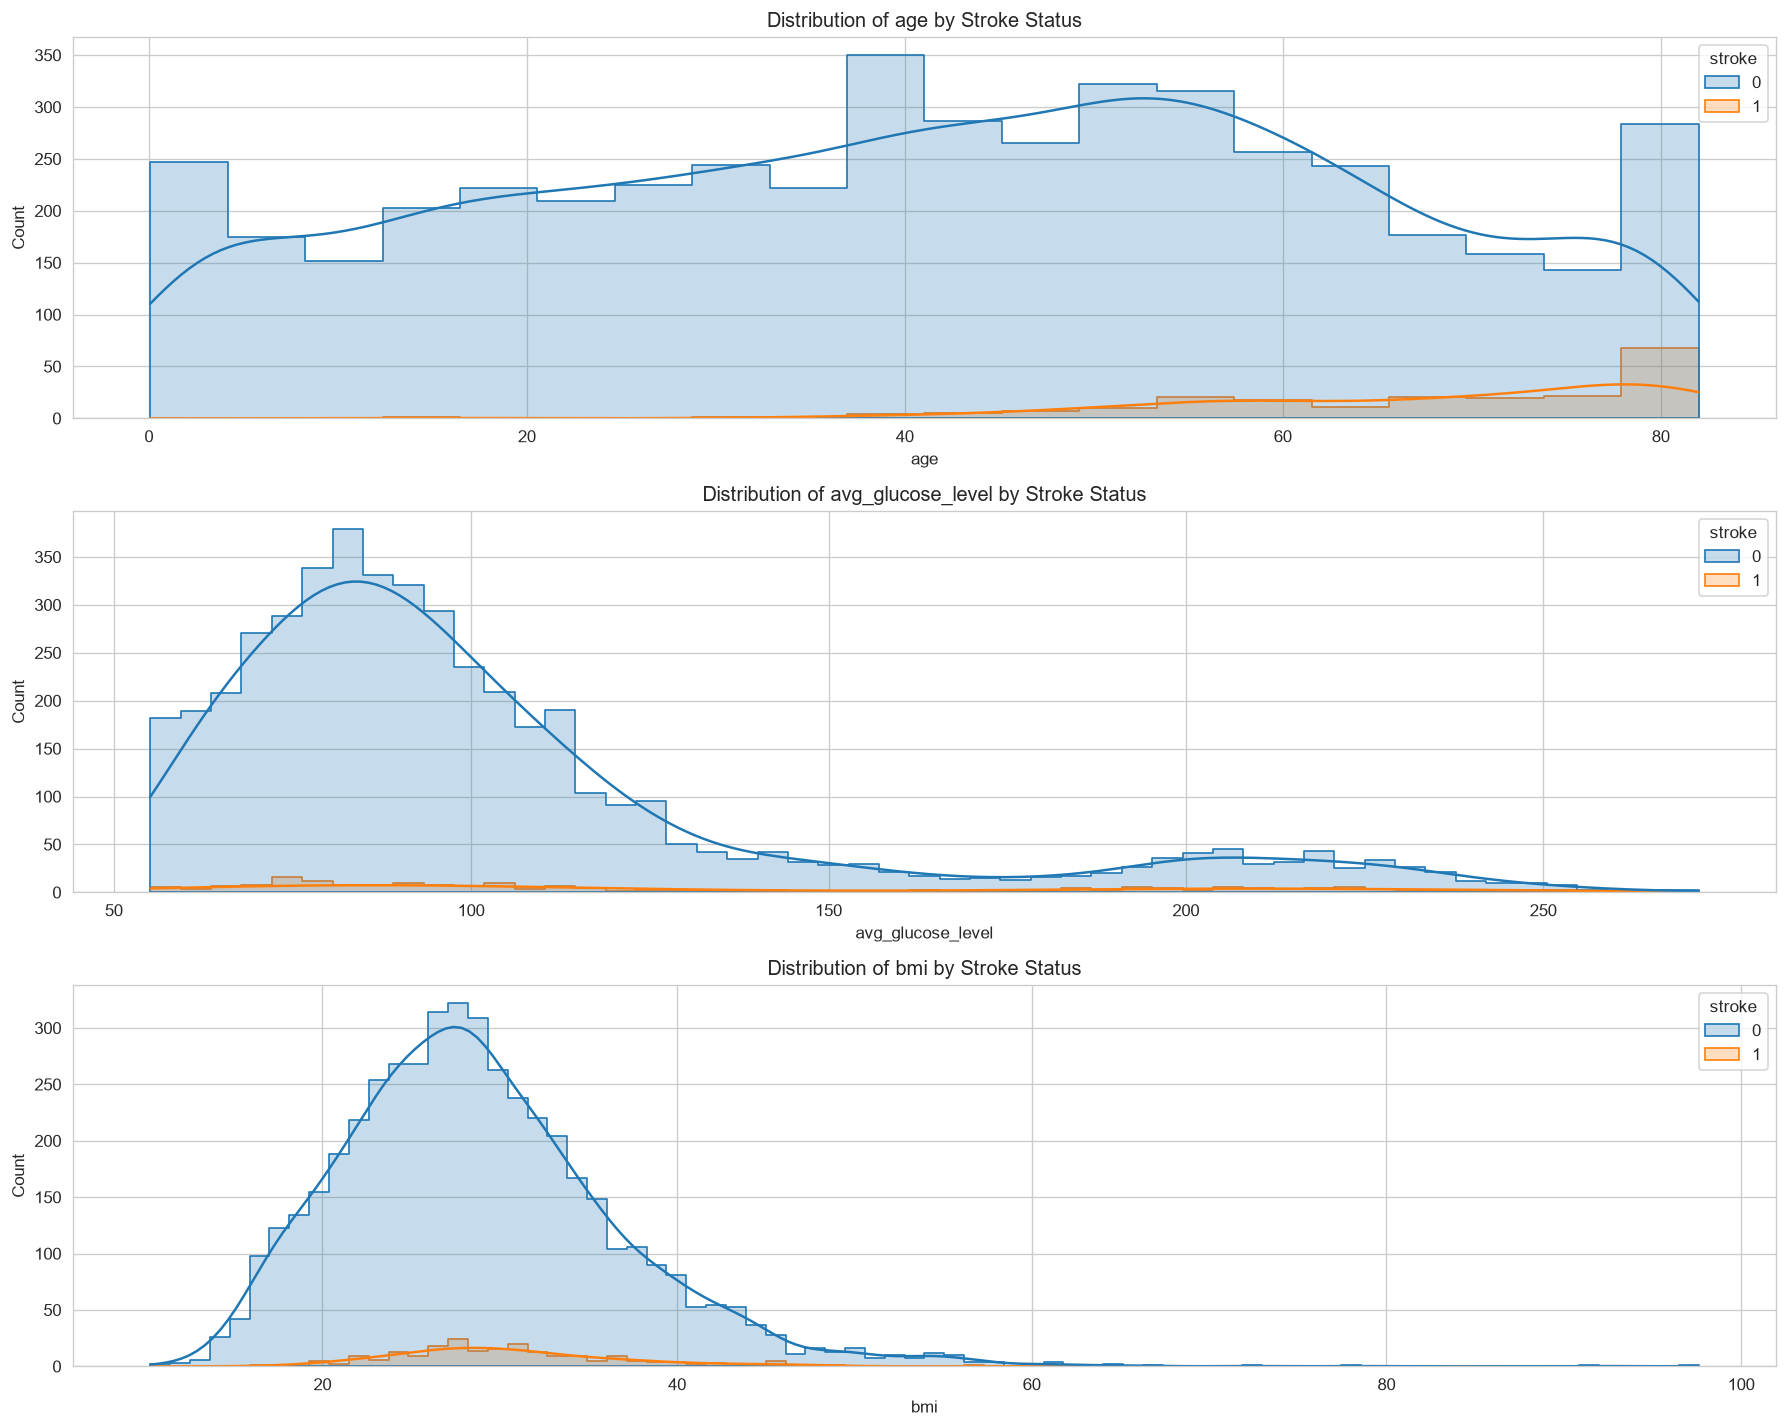

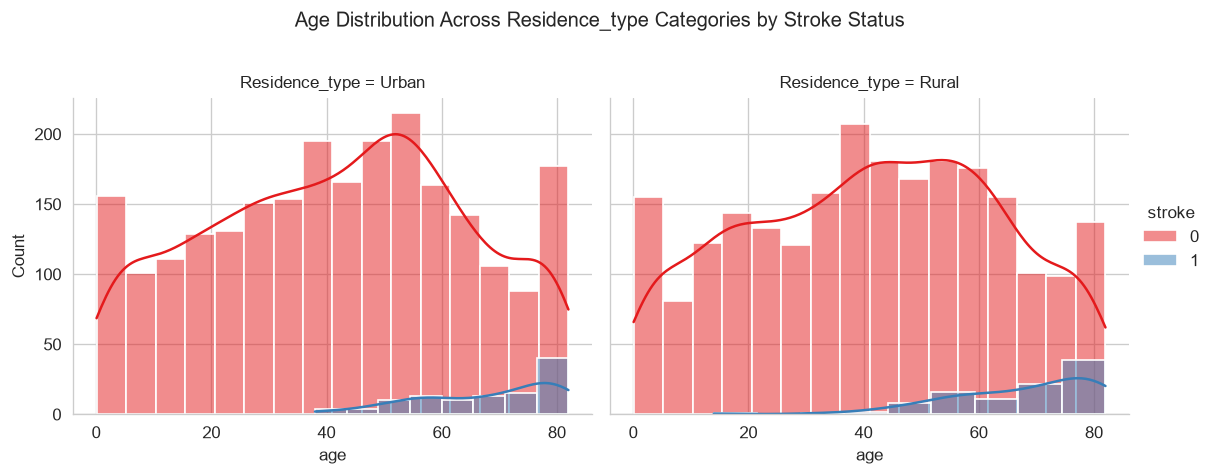

In [3]:
# Distribution plots for numerical features by Gender, Residence Type, and Stroke status
num_cols = ['age', 'avg_glucose_level', 'bmi']
categorical_groups = ['gender', 'Residence_type']

def grid_histograms_by_group(df, num_cols, cat_groups):
    for cat in cat_groups:
        # Plot distributions for each numerical feature split by stroke status
        plt.figure(figsize=(15, 4 * len(num_cols)))
        for i, col in enumerate(num_cols, 1):
            plt.subplot(len(num_cols), 1, i)
            sns.histplot(
                data=df, 
                x=col, 
                hue='stroke', 
                kde=True, 
                element='step',
                common_norm=False
            )
            plt.title(f'Distribution of {col} by Stroke Status')
        plt.tight_layout()
        plt.show()

        # Detailed breakdown across Gender/Residence Type categories and Stroke
        g = sns.FacetGrid(df, col=cat, hue='stroke', height=4, aspect=1.2, palette='Set1')
        g.map_dataframe(sns.histplot, x='age', kde=True, alpha=0.5)
        g.add_legend()
        g.fig.subplots_adjust(top=0.8)
        g.fig.suptitle(f'Age Distribution Across {cat.capitalize()} Categories by Stroke Status')
        plt.show()

# Execute function in cell
grid_histograms_by_group(data, num_cols, categorical_groups)

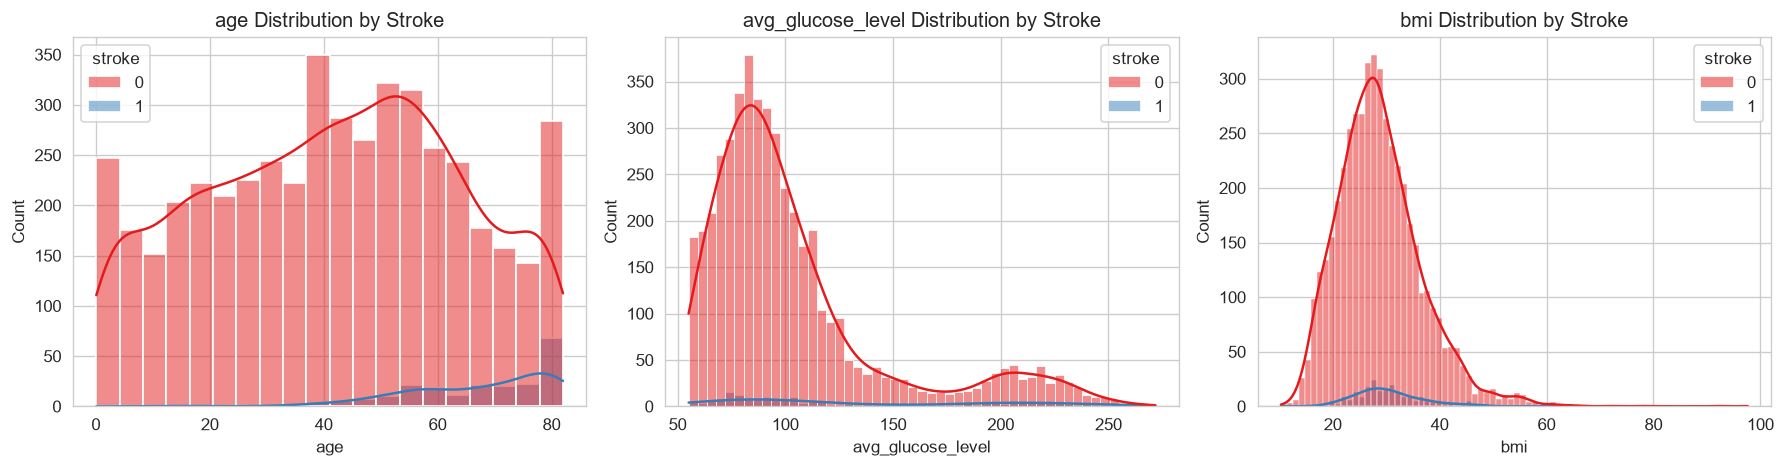

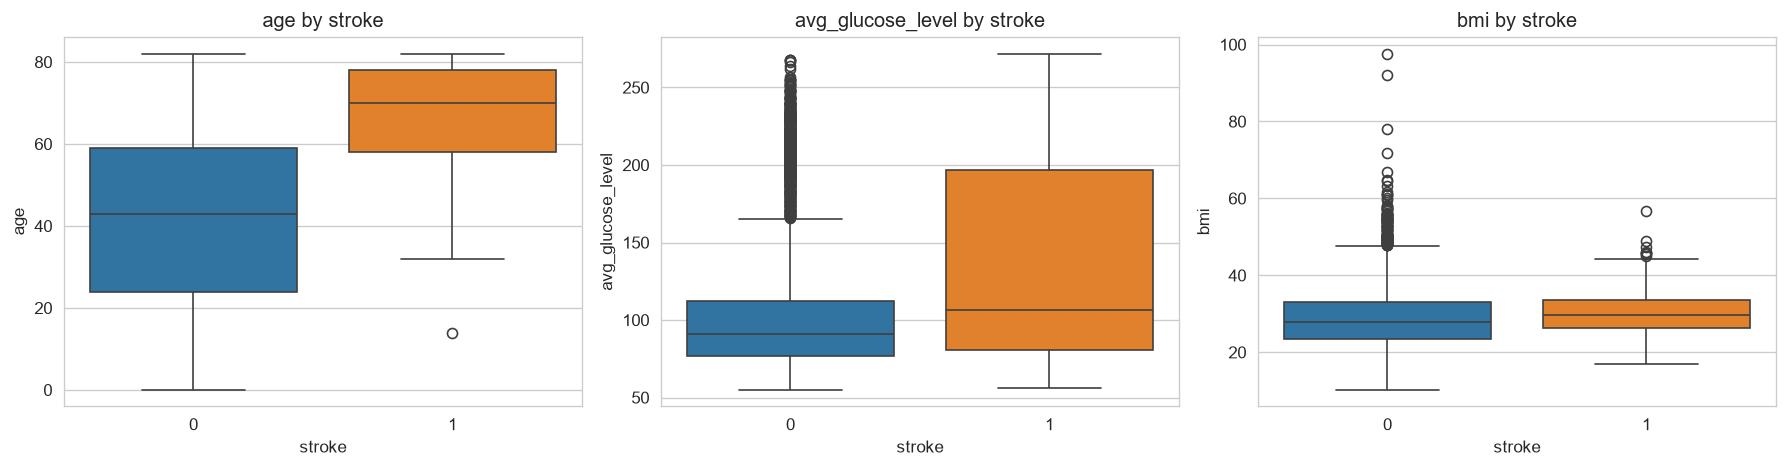

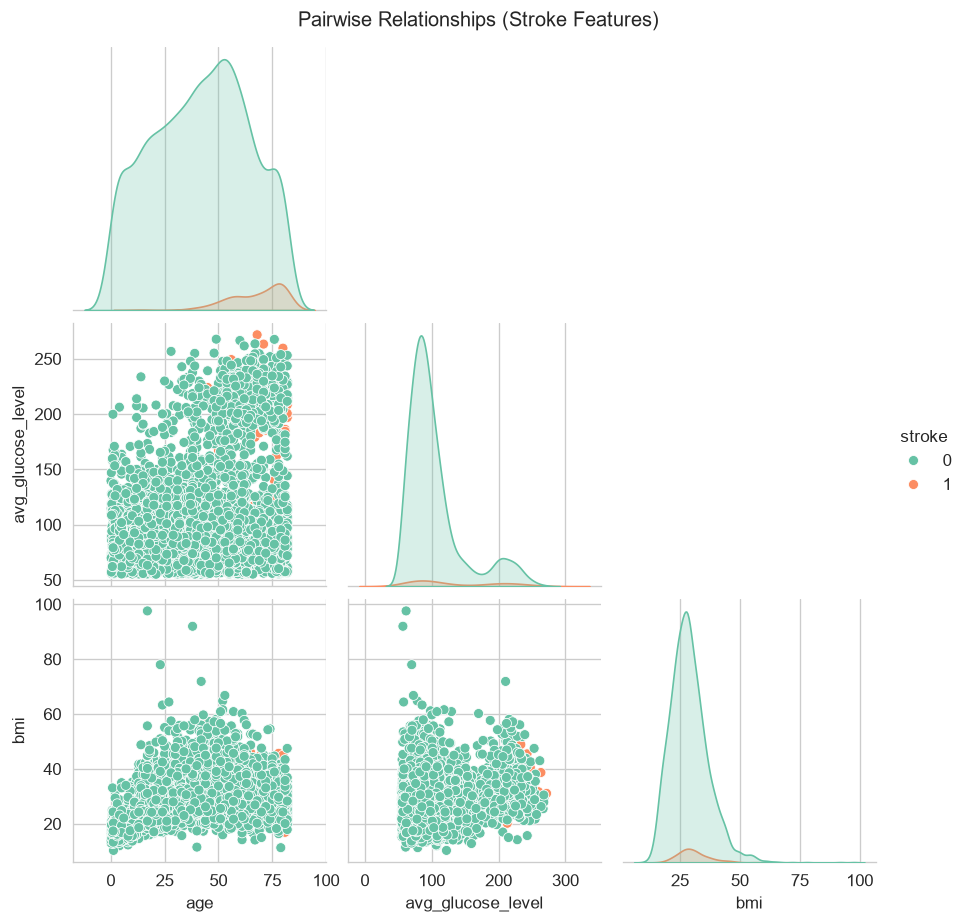

C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:4270: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


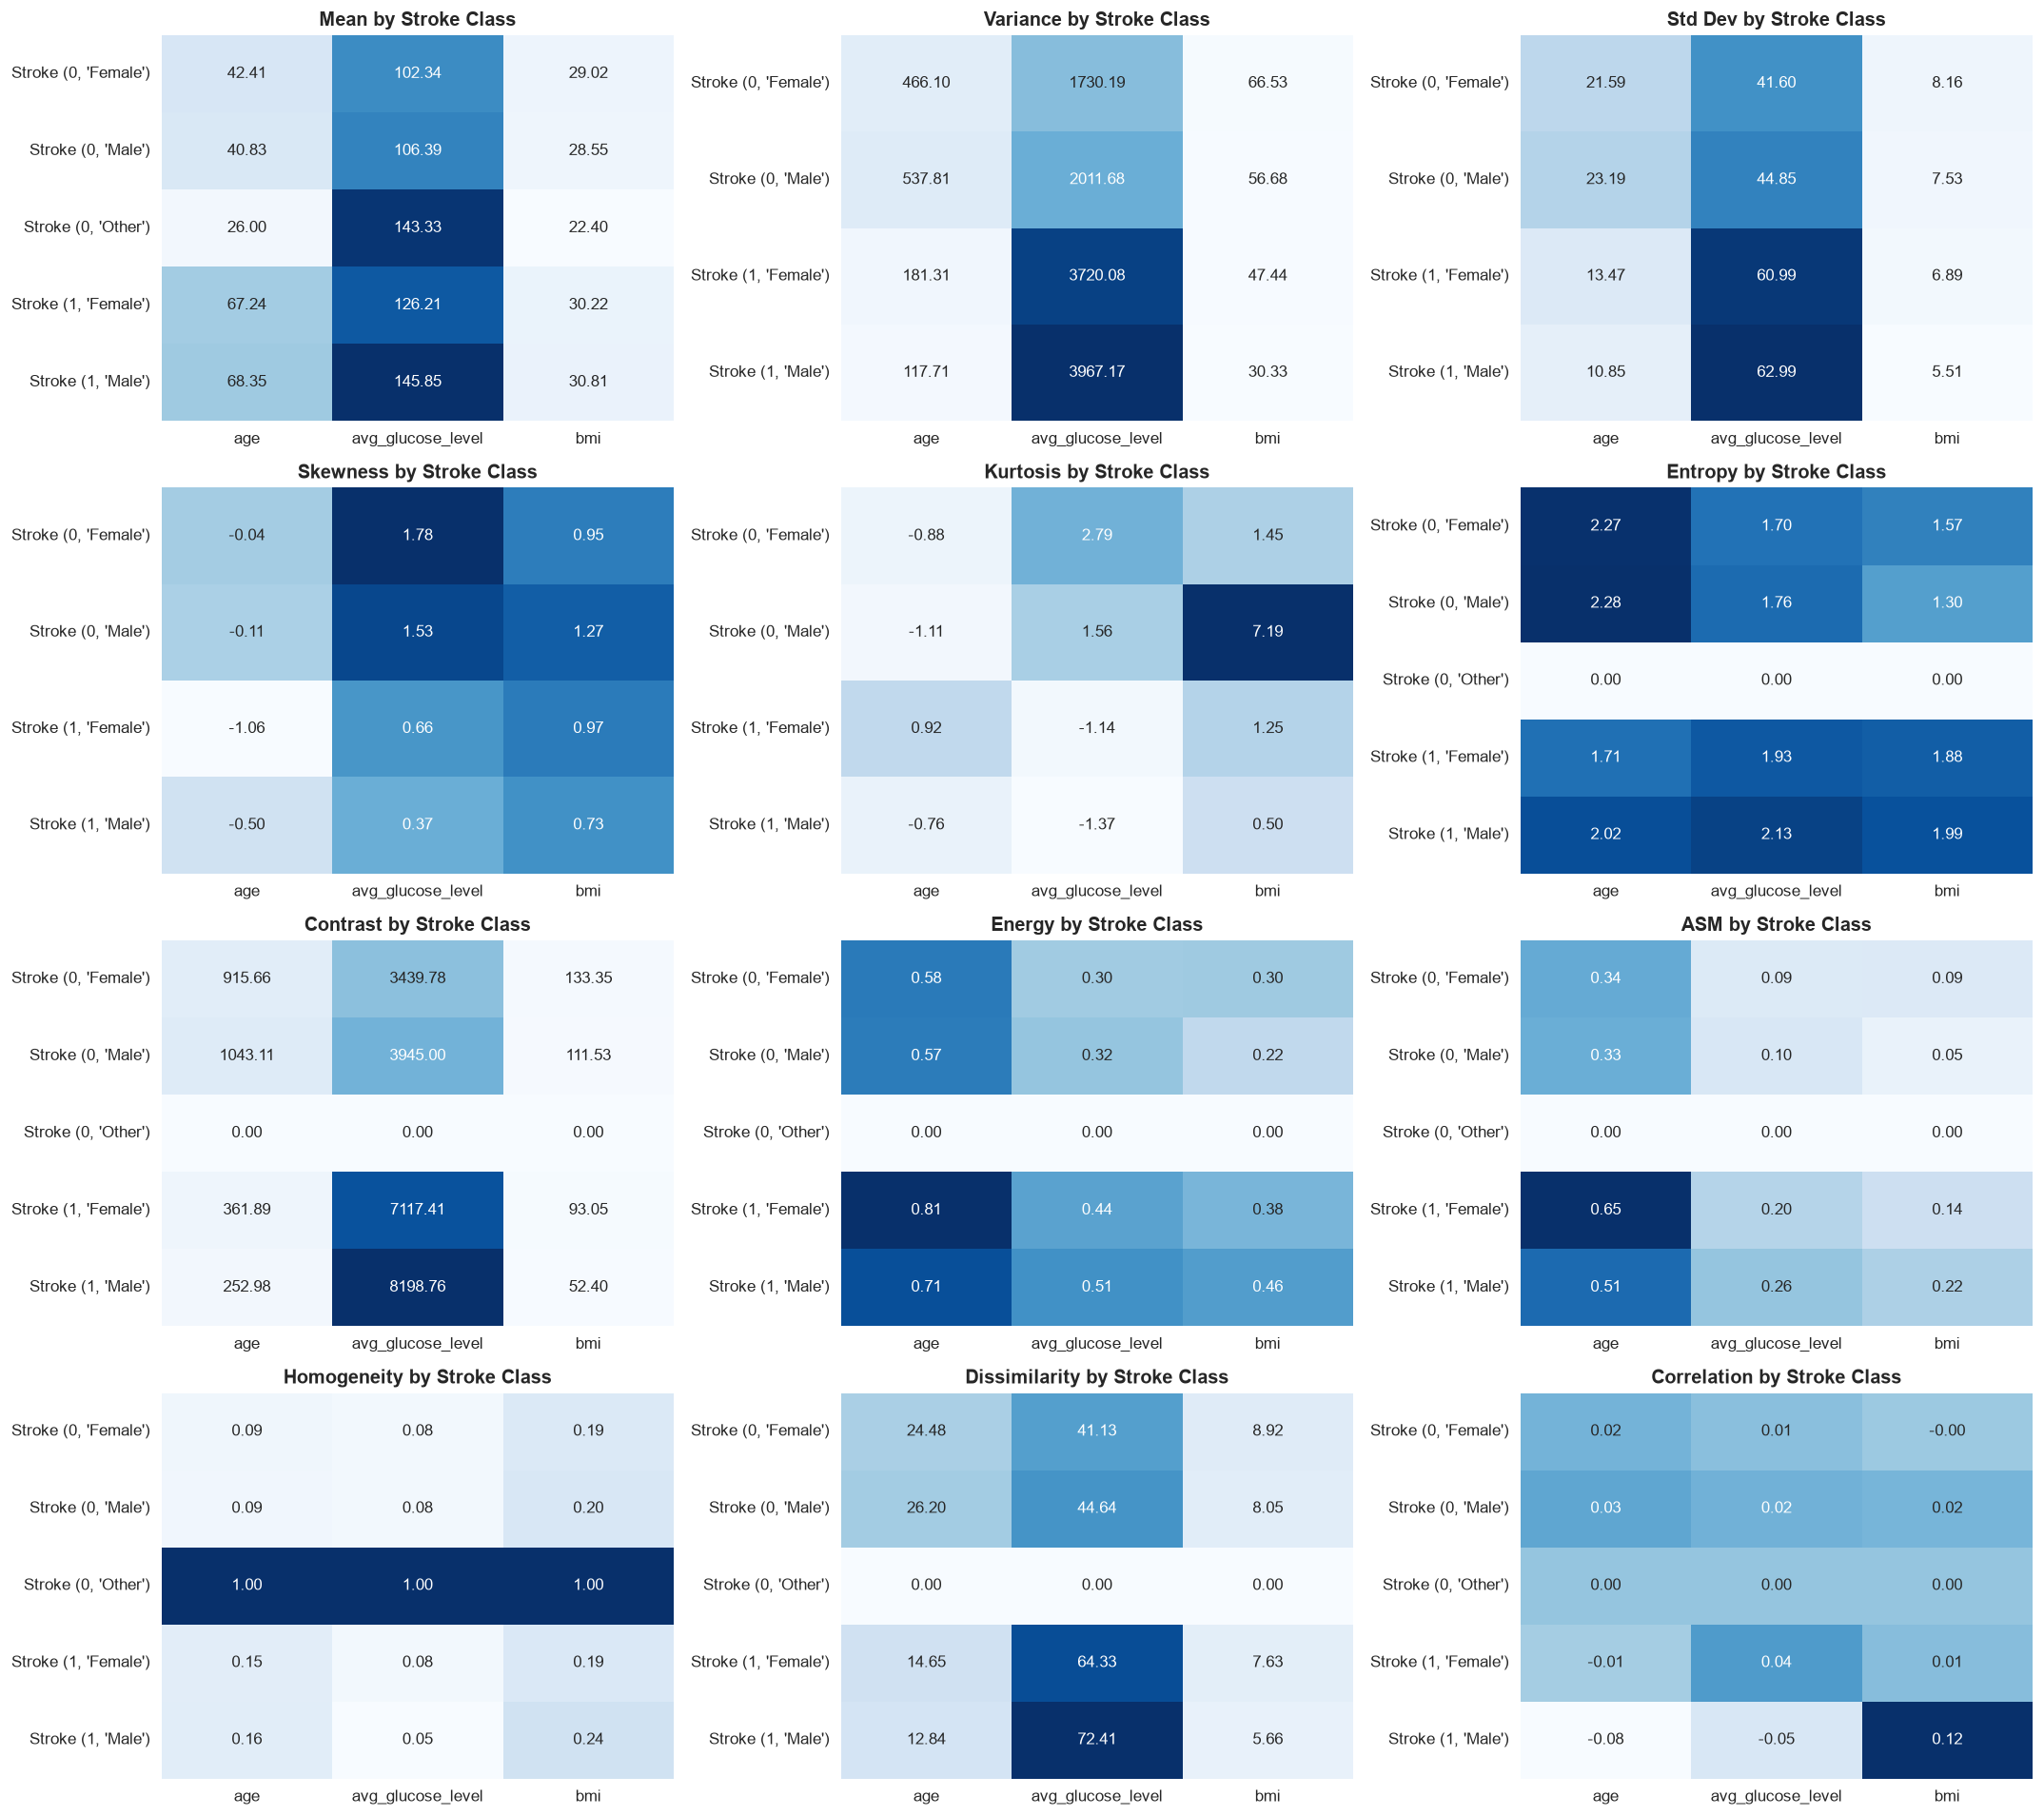

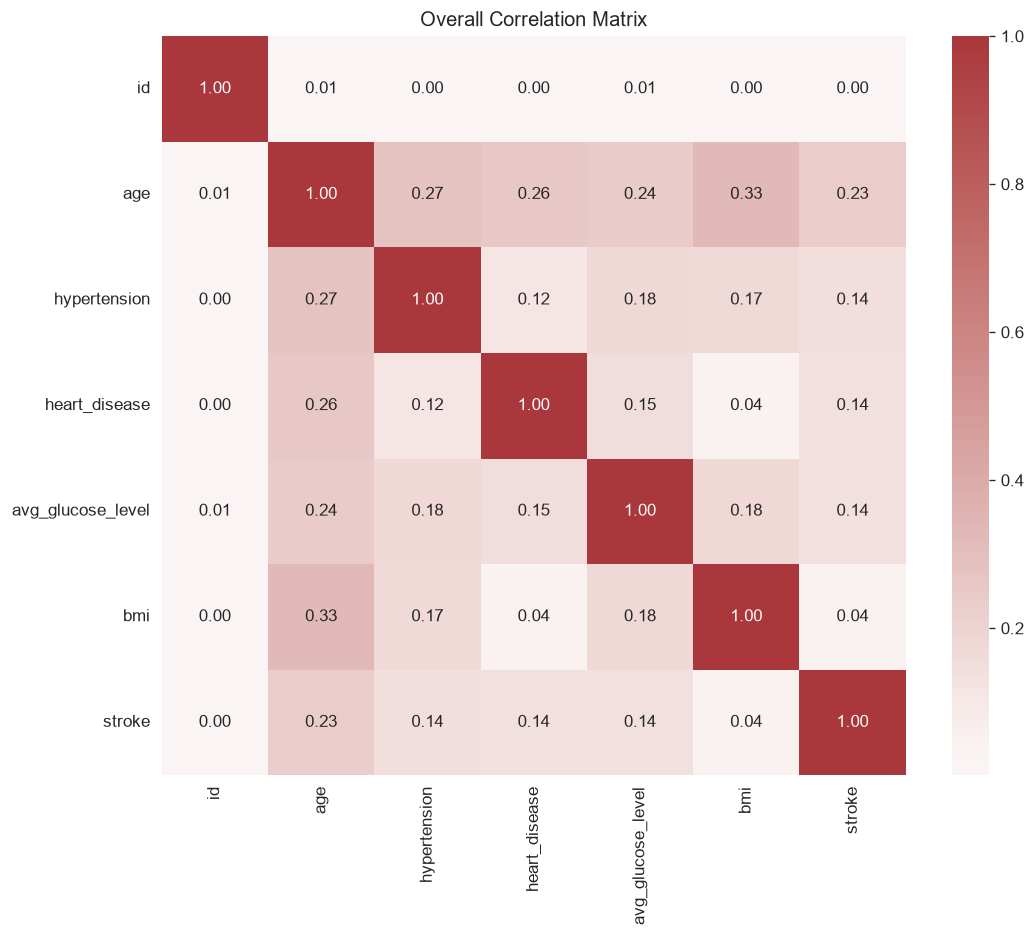

In [4]:
from scipy.stats import skew, kurtosis, entropy

# Select continuous numerical columns
num_cols_temp = ['age', 'avg_glucose_level', 'bmi']

# 1. Distribution Histograms grouped by stroke status
plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols_temp, 1):
    plt.subplot(1, 3, i)

    classes = data['stroke'].unique()
    can_use_kde = all(data[data['stroke'] == c][col].nunique() > 1 for c in classes)

    sns.histplot(data, x=col, hue='stroke', kde=can_use_kde, palette='Set1', alpha=0.5)
    plt.title(f'{col} Distribution by Stroke')
plt.tight_layout()
plt.show()

# 2. Boxplots grouped by stroke class
def boxplots_by_label(df, features, label='stroke'):
    plt.figure(figsize=(15, 4))
    for i, f in enumerate(features, 1):
        plt.subplot(1, 3, i)
        sns.boxplot(x=label, y=f, data=df, hue=label, palette=['#1f77b4', '#ff7f0e'], legend=False)
        plt.title(f'{f} by {label}')
    plt.tight_layout()
    plt.show()

boxplots_by_label(data, num_cols_temp)

# 3. Pairwise Relationships
df_pair = data[num_cols_temp + ["stroke"]]

sns.pairplot(
    df_pair,
    hue="stroke",
    corner=True,
    palette="Set2"
)
plt.suptitle("Pairwise Relationships (Stroke Features)", y=1.02)
plt.show()

# 4. Detailed Statistical and Texture/Signal Analysis by Stroke Class
def compute_class_stats(df, num_cols, label='stroke'):
    records = []
    ### grouped = df.groupby(label)
    grouped = df.groupby([label, 'gender'])
    
    for stroke_val, group in grouped:
        for col in num_cols:
            vals = group[col].dropna().values
            if len(vals) == 0:
                continue
            
            # Statistical Metrics
            m = np.mean(vals)
            var = np.var(vals, ddof=1)
            std = np.std(vals, ddof=1)
            sk = skew(vals)
            kt = kurtosis(vals)
            
            # Entropy
            hist, _ = np.histogram(vals, bins=10, density=True)
            hist = hist[hist > 0]
            ent = entropy(hist)
            
            # Signal / Distribution Proxies (Contrast, Dissimilarity, ASM, Energy, Homogeneity, Correlation)
            contrast = np.mean(np.diff(vals)**2) if len(vals) > 1 else 0
            dissimilarity = np.mean(np.abs(np.diff(vals))) if len(vals) > 1 else 0
            
            vals_norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-8)
            asm = np.sum(vals_norm**2) / len(vals_norm)
            energy = np.sqrt(asm)
            
            homogeneity = np.mean(1.0 / (1.0 + np.abs(np.diff(vals)))) if len(vals) > 1 else 1.0
            
            corr = pd.Series(vals).autocorr(lag=1) if len(vals) > 1 else 0.0
            if np.isnan(corr):
                corr = 0.0

            records.append({
                'Stroke': f'Stroke {stroke_val}',
                'Feature': col,
                'Mean': m,
                'Variance': var,
                'Std Dev': std,
                'Skewness': sk,
                'Kurtosis': kt,
                'Entropy': ent,
                'Contrast': contrast,
                'Energy': energy,
                'ASM': asm,
                'Homogeneity': homogeneity,
                'Dissimilarity': dissimilarity,
                'Correlation': corr
            })
            
    return pd.DataFrame(records)

df_stats = compute_class_stats(data, num_cols_temp)

metrics = ['Mean', 'Variance', 'Std Dev', 'Skewness', 'Kurtosis', 'Entropy', 
           'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    pivot_df = df_stats.pivot_table(index='Stroke', columns='Feature', values=metric)
    sns.heatmap(pivot_df, annot=True, fmt=".2f", cmap="Blues", ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{metric} by Stroke Class', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('')

plt.tight_layout()
plt.show()

# Full Correlation Matrix at the End
def corr_heatmap(df):
    corr = df.corr(numeric_only=True)
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap='vlag', center=0)
    plt.title('Overall Correlation Matrix')
    plt.show()

corr_heatmap(data)

C:\Users\HP\AppData\Local\Temp\ipykernel_8540\1652156649.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')
C:\Users\HP\AppData\Local\Temp\ipykernel_8540\1652156649.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')
C:\Users\HP\AppData\Local\Temp\ipykernel_8540\1652156649.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')


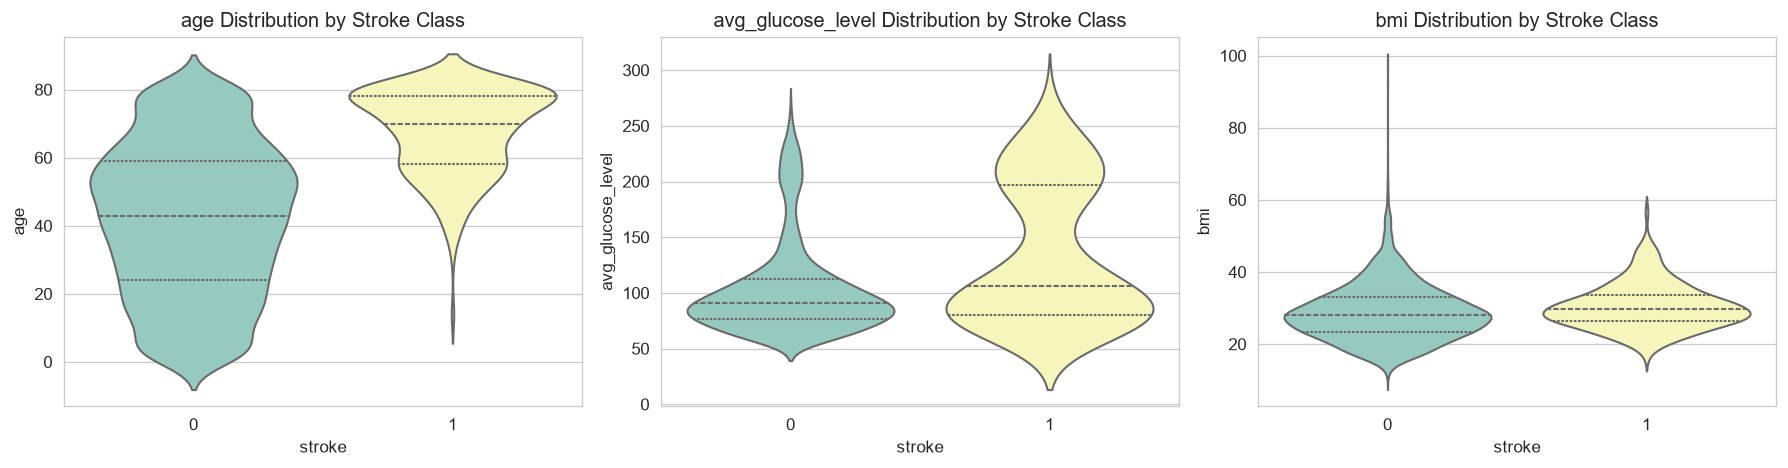

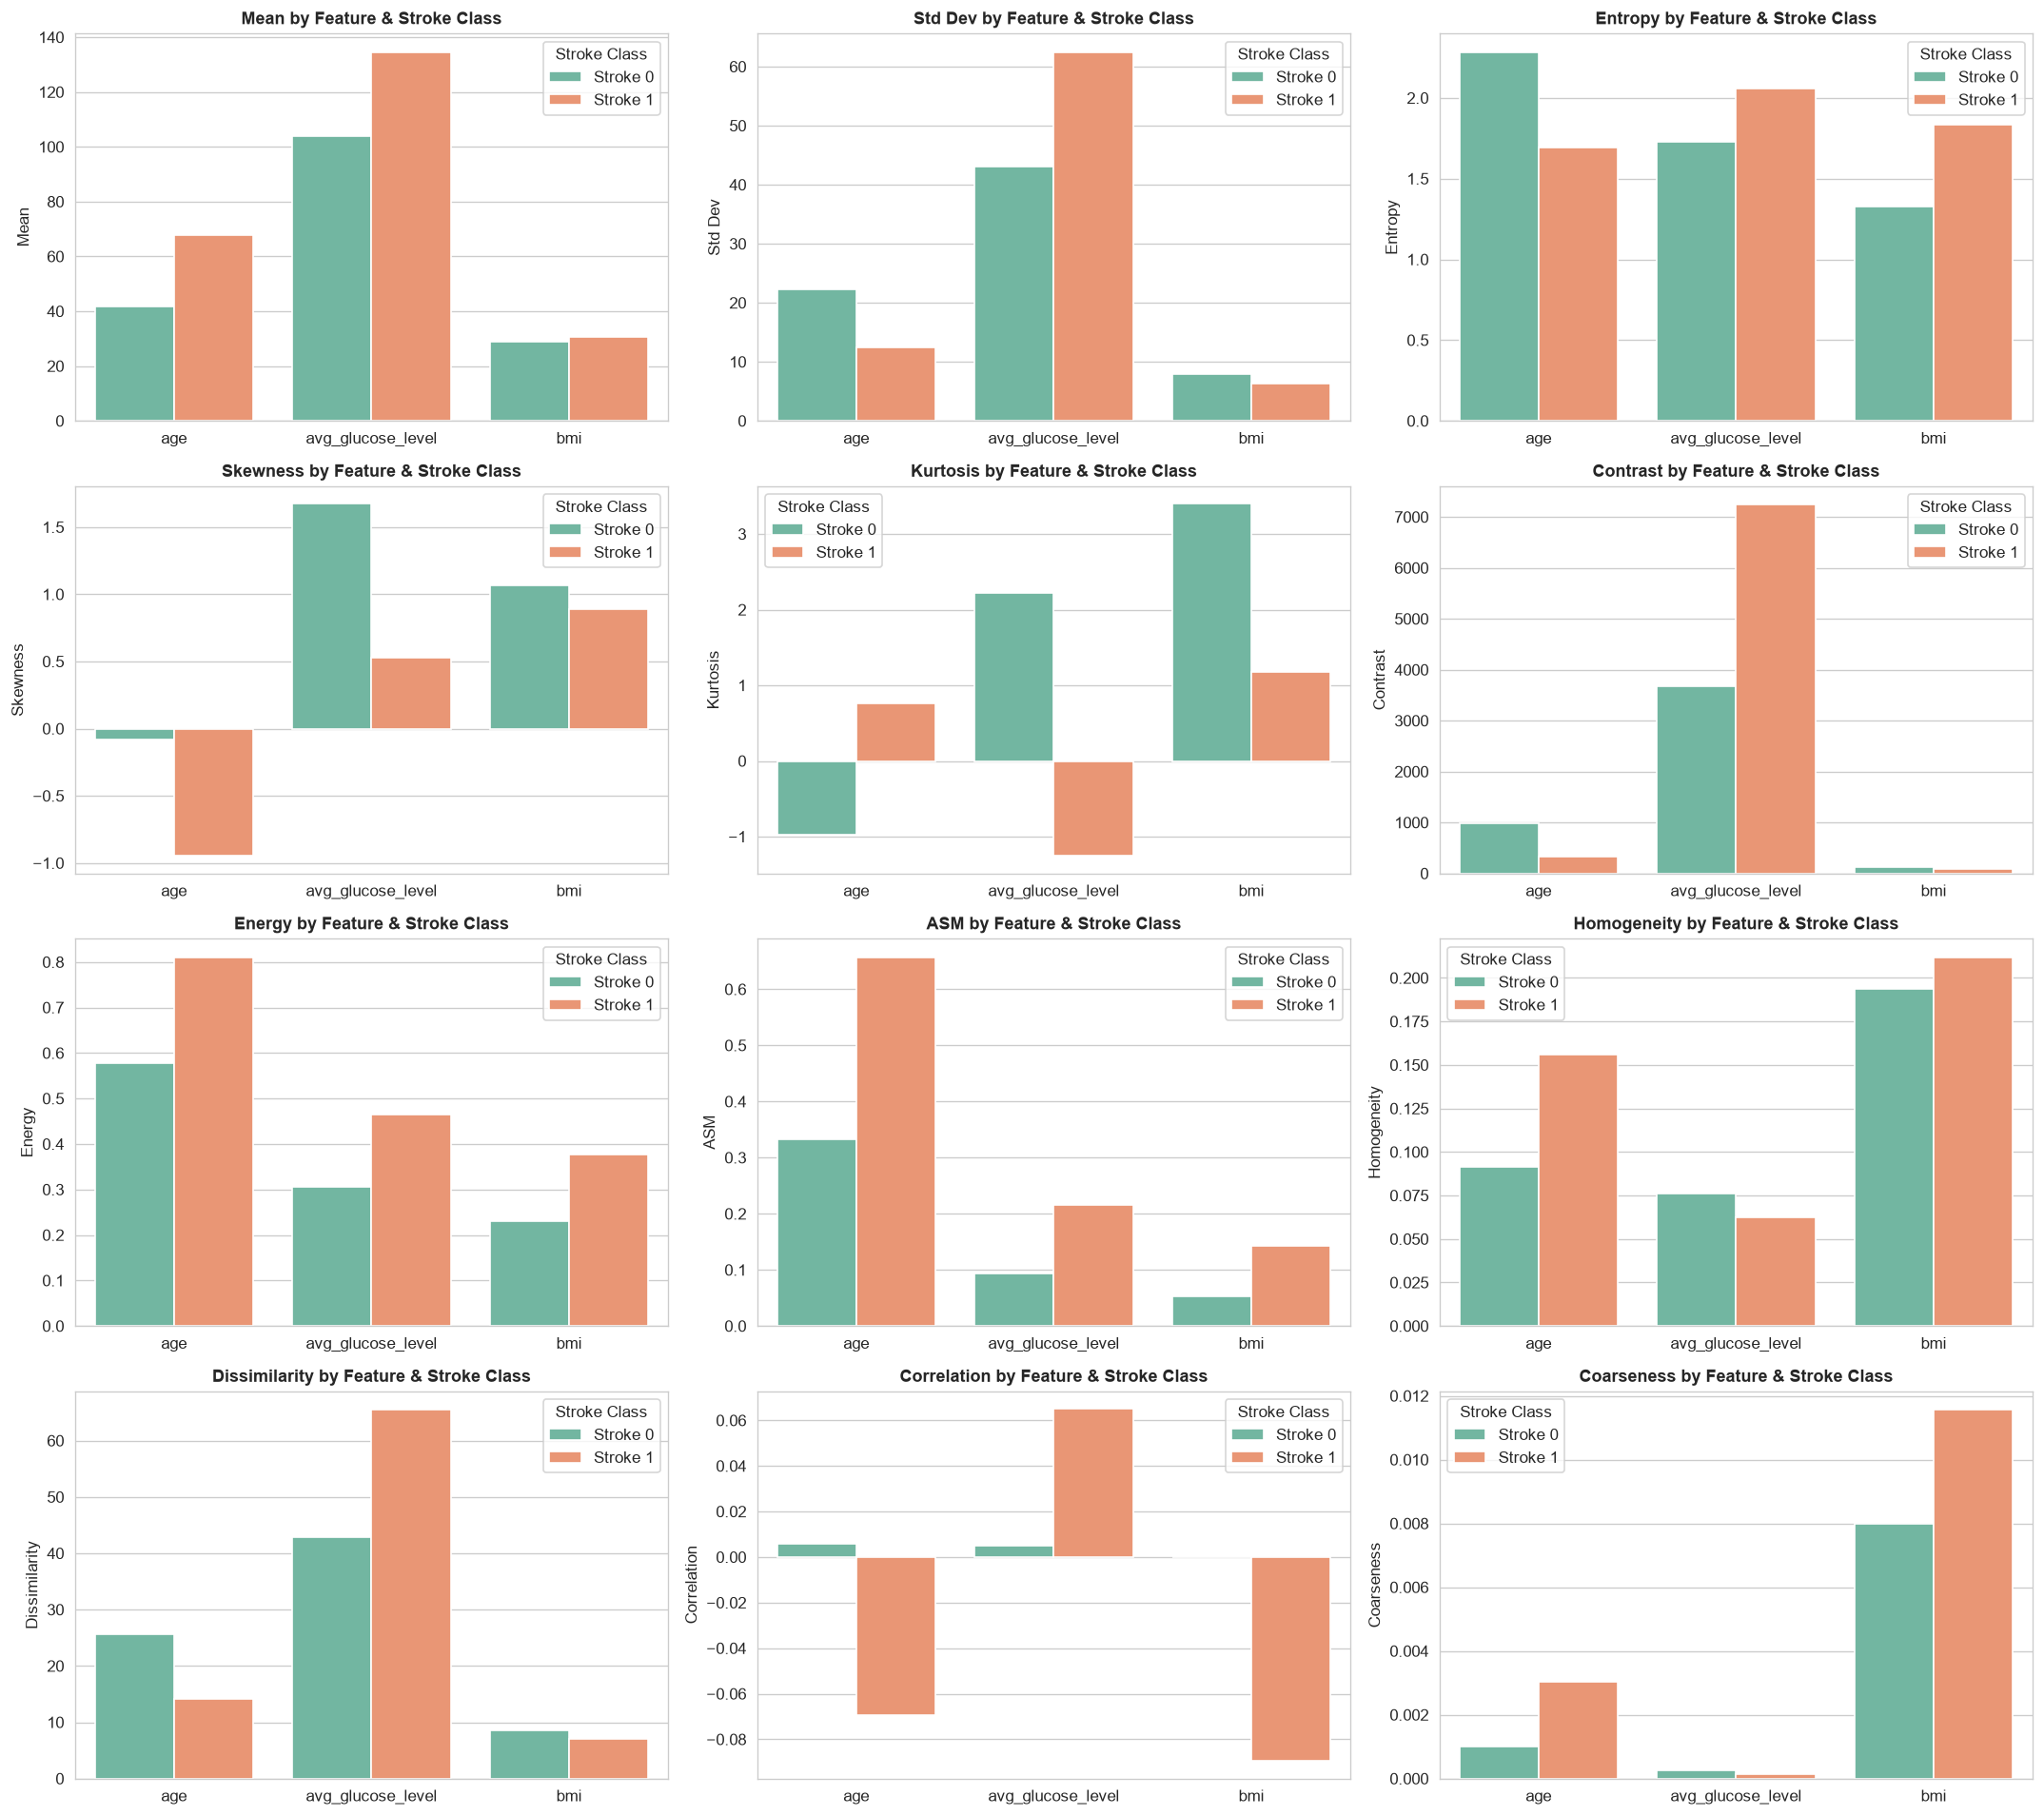

In [5]:
# 1. Violin Plots (Distribution + Density by Stroke Class)
num_cols = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')
    plt.title(f'{col} Distribution by Stroke Class')
plt.tight_layout()
plt.show()

# 2. Function to Compute All Metrics
def compute_metrics(df, features, label='stroke'):
    records = []
    for stroke_val, group in df.groupby(label):
        for col in features:
            vals = group[col].dropna().values
            if len(vals) == 0:
                continue
            
            m, std, sk, kt = np.mean(vals), np.std(vals, ddof=1), skew(vals), kurtosis(vals)
            hist, _ = np.histogram(vals, bins=10, density=True)
            ent = entropy(hist[hist > 0])
            
            diffs = np.diff(vals) if len(vals) > 1 else np.array([0])
            contrast = np.mean(diffs**2)
            dissimilarity = np.mean(np.abs(diffs))
            
            vals_norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-8)
            asm = np.sum(vals_norm**2) / len(vals_norm)
            energy = np.sqrt(asm)
            
            homogeneity = np.mean(1.0 / (1.0 + np.abs(diffs)))
            corr = pd.Series(vals).autocorr(lag=1) if len(vals) > 1 else 0.0
            corr = 0.0 if np.isnan(corr) else corr
            coarseness = 1.0 / (contrast + 1e-8)

            records.append({
                'Stroke Class': f'Stroke {stroke_val}', 'Feature': col,
                'Mean': m, 'Std Dev': std, 'Entropy': ent, 'Skewness': sk, 'Kurtosis': kt,
                'Contrast': contrast, 'Energy': energy, 'ASM': asm,
                'Homogeneity': homogeneity, 'Dissimilarity': dissimilarity,
                'Correlation': corr, 'Coarseness': coarseness
            })
    return pd.DataFrame(records)

# 3. Calculate Metrics Dataframe
metrics_df = compute_metrics(data, num_cols)

# 4. Visualizations for Each Statistical & Texture Metric
metrics_list = [
    'Mean', 'Std Dev', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast',
    'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness'
]

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for idx, metric in enumerate(metrics_list):
    sns.barplot(
        data=metrics_df, 
        x='Feature', 
        y=metric, 
        hue='Stroke Class', 
        palette='Set2', 
        ax=axes[idx]
    )
    axes[idx].set_title(f'{metric} by Feature & Stroke Class', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel(metric)

plt.tight_layout()
plt.show()

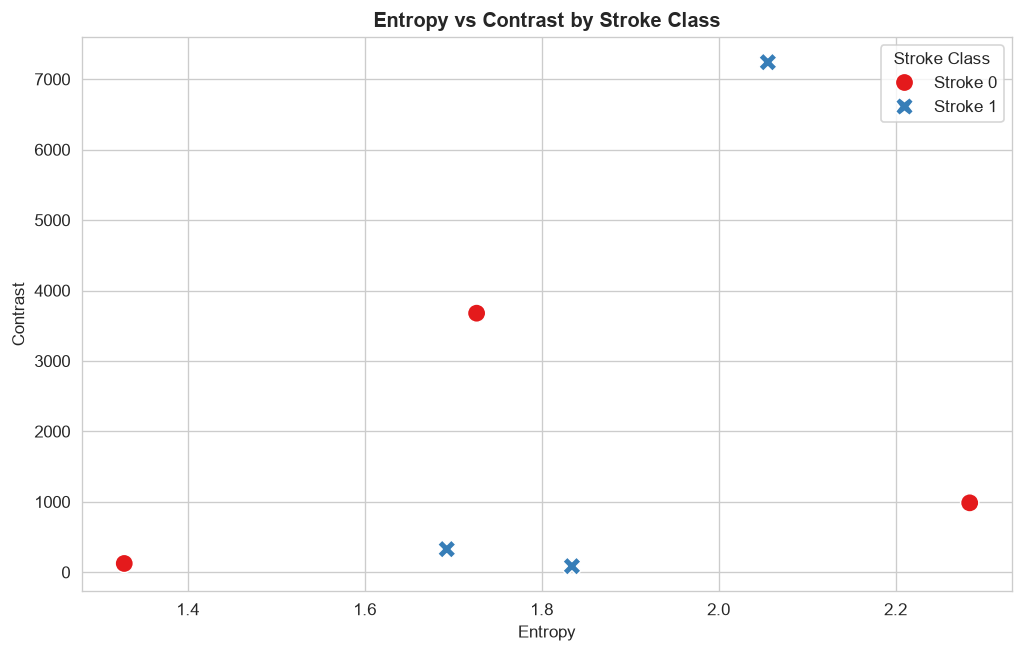

In [6]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=metrics_df, 
    x='Entropy', 
    y='Contrast', 
    hue='Stroke Class', 
    style='Stroke Class', 
    s=120, 
    palette='Set1'
)
plt.title('Entropy vs Contrast by Stroke Class', fontsize=12, fontweight='bold')
plt.show()

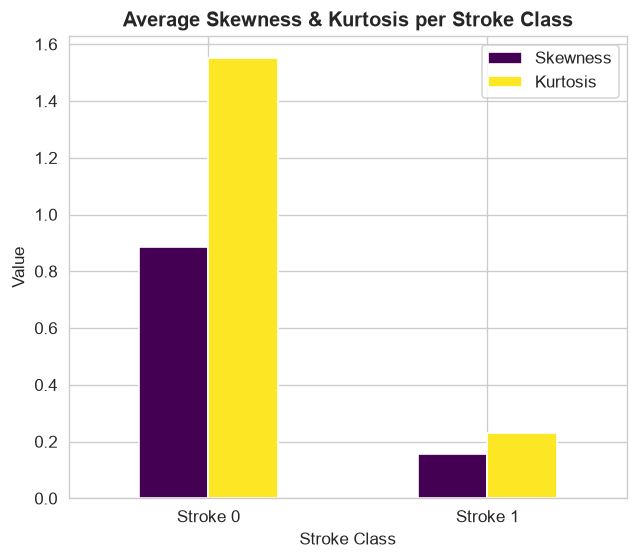

In [7]:
# Average Skewness & Kurtosis per Stroke Class
skew_kurt = metrics_df.groupby('Stroke Class')[['Skewness', 'Kurtosis']].mean()

skew_kurt.plot(kind='bar', figsize=(6, 5), rot=0, colormap='viridis')
plt.title('Average Skewness & Kurtosis per Stroke Class', fontsize=12, fontweight='bold')
plt.ylabel('Value')
plt.show()